# 10 Байесовские модели

**Цель работы:** с помощью средств и библиотек языка программирования Python обучить модели на основе баейсовского подхода.

**Выполнил:** ст.группы 24ВВИ1 Будников А.С.

## Теоретическая часть

### 1. В чём состоит байесовский подход к решению задач классификации?

Байесовский подход к решению задачи классификации основан на вычислении вероятности принадлежности объекта к классам с учетом его признаков. Для вычисления этих вероятностей используется теорема Байеса, которая дает возможность рассчитать вероятность класса при известных признаках.  

### 2. Сформулируйте формулу теоремы Байеса и поясните смысл каждого её элемента.

Формула теоремы Байеса имеет вид: 

\\( P(A|B)=\frac{P(B|A)*P(A)}{P(B)} \\),

где P(A|B) - условная вероятность события А при условии наличия у него признаков В,

P(B|A) - вероятность увидеть признаки B при наблюдении объекта класса A,

P(A) - вероятность принадлежности объекта к классу А без учета признаков (текущ./общ.),

P(B) - вероятность появления в данных признаков B.

В рассматирваемой задаче классификации A - определенный класс, а B - наблюдаемые признаки данного объекта. Для каждого класса вычисляется вероятность с учетом признаков, а потом выбирается наибольшая.

### 3. Что означает допущение условной независимости признаков в наивном байесовском классификаторе?

В наивном байесовском классификаторе допущение об условной независимости признаков означает, что при известном классе значение одного признака не влияет на появление другого признака, то есть не коррелируют между собой, что в данных вряд ли встречается. По крайней мере в используемой выборке признаки частично коррелируют, а возможно эти взаимодействия сложнее отследить. Делается это для того, чтобы разложить общую вероятность на вектор вероятностей каждого признака для заданного класса. Далее элементы вектора перемножаются для получения общей вероятности.

### 4. В чём различие между: априорной вероятностью; апостериорной вероятностью?

Априорная вероятность - это вероятность принадлежности объекта к определённому классу до учёта его признаков. Возможно оценивается по доле объектов каждого класса в обучающей выборке. Апостериорная вероятность - это вероятность принадлежности объекта к классу после учёта его признаков. Рассчитывается уже с помощью теоремы Байеса. Таким образом, априорная вероятность отражает исходную частоту класса, а апостериорная учитывает дополнительную информацию об объекте.

### 5. Какие преимущества и ограничения имеют байесовские модели по сравнению с линейными моделями?

К преимуществам можно отнести, что байесовские модели позволяют оценить вероятности принадлежности объекта к классу и быстро обучаются, могут хорошо работать на сравнительно небольших выборках и служить базовым решением в некоторых задачах, даже более простым, чем линейные модели. Однако байесовские модели имеют ряд ограничений. Например, предположение о независимости признаков скорее всего не будет выполняться, а нормальное распределения для гауссовского классификатора выглядит трудно достижимым. Нельзя не отметить, что качество байесовских моделей в полной мере зависит от того, насколько предположения и допущения метода буду выполняться. Линейные модели же строят зависимости или линейные границы, поэтому могут быть более точными. 

## Практическая часть

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import BernoulliNB

import time

from sklearn.metrics import (classification_report, confusion_matrix)

In [2]:
train_t = pd.read_csv('data/covtype-t.csv')
test_t = pd.read_csv('data/covtype-t-test.csv')

train = pd.read_csv('data/covtype-7-ss.csv')
test = pd.read_csv('data/covtype-7-test-ss.csv')

train_pca = pd.read_csv('data/train_bin44_pca2.csv')
test_pca = pd.read_csv('data/test_bin44_pca2.csv')

print(f'Train shape={train.shape}')
print(f'Test shape={test.shape}')
print()
print(f'PCA Train shape={train_pca.shape}')
print(f'PCA Test shape={test_pca.shape}')
print()

X_train = train.drop(columns=['Тип_лесного_покрова'])
y_train = train['Тип_лесного_покрова']
X_test = test.drop(columns=['Тип_лесного_покрова'])
y_test = test['Тип_лесного_покрова']

X_train_pca = train_pca.drop(columns=['Тип_лесного_покрова'])
y_train_pca = train_pca['Тип_лесного_покрова']
X_test_pca = test_pca.drop(columns=['Тип_лесного_покрова'])
y_test_pca = test_pca['Тип_лесного_покрова']

X_train_t = train_t.drop(columns=['Тип_лесного_покрова'])
y_train_t = train_t['Тип_лесного_покрова']
X_test_t = test_t.drop(columns=['Тип_лесного_покрова'])
y_test_t = test_t['Тип_лесного_покрова']

print(f'X_train={X_train.shape}\ty_train={y_train.shape}')
print(f'X_test={X_test.shape}\ty_test={y_test.shape}')
print()
print(f'X_train_pca={X_train_pca.shape}\ty_train_pca={y_train_pca.shape}')
print(f'X_test_pca={X_test_pca.shape}\ty_test_pca={y_test_pca.shape}')
print()
print(f'X_train_t={X_train_t.shape}\ty_train_t={y_train_t.shape}')
print(f'X_test_t={X_test_t.shape}\ty_test_t={y_test_t.shape}')

Train shape=(317254, 48)
Test shape=(116194, 48)

PCA Train shape=(317254, 47)
PCA Test shape=(116194, 47)

X_train=(317254, 47)	y_train=(317254,)
X_test=(116194, 47)	y_test=(116194,)

X_train_pca=(317254, 46)	y_train_pca=(317254,)
X_test_pca=(116194, 46)	y_test_pca=(116194,)

X_train_t=(317254, 54)	y_train_t=(317254,)
X_test_t=(116194, 54)	y_test_t=(116194,)


## Анализ

В качестве датасета используется [Forest Cover Types](https://www.kaggle.com/datasets/uciml/forest-cover-type-dataset/data).
Здесь содержатся данные о типах лесного покрова для территорий национального парка Рузвельта в Колорадо США. Каждая строка таблицы описывает один участок земли площадью 30×30 метров. Набор признаков включает информацию о типе дерева, степени затенения, расстоянии до близлежащих ориентиров (дорог и т. д.), типе почвы и местном рельефе.

Всего в датасете 581 012 записей и 55 столбцов, однако в результате проделанной работы количество строк значительно сократилось. Для удобства чтения столбцы были переименованы.

Расшифрока значений целевой переменной:

1. Ель/Пихра
2. Сосна скрученная
3. Сосна пондероза
4. Тополь/Ива
5. Осина
6. Дугласова пихта
7. Круммхольц

На текущем этапе датасет уже прошел этапы очистки, масштабирования и отбора признаков в работах 5,6 и 7 соответственно, а также сэмплинг. Отмечу, что с самого начала данные делим на обучающую, или тренировочную, и тестовую выборки.

В данной работе будем использовать 2 выборки. Первая - до выделения признаков и после отбора, вторая - после выделения признаков. Также ради эксперимента используется выборка на момент до отбора признаков, предварительно прошедшая сэмплинг. Такой подход позволит оценить качество компонент, созданных в работе №8, и целесообразность применения метода PCA, и других методов отбора к используемому набору данных.

In [3]:
gnb = GaussianNB()
start = time.time()
gnb.fit(X_train, y_train)
time_gnb = time.time() - start

y_pred_gnb = gnb.predict(X_test)
y_pred_gnb

array([7, 7, 5, ..., 5, 5, 7], shape=(116194,))

In [4]:
print(classification_report(y_test, y_pred_gnb))

              precision    recall  f1-score   support

           1       0.73      0.01      0.02     42367
           2       0.90      0.11      0.19     56653
           3       0.30      0.40      0.34      7151
           4       0.08      1.00      0.14       549
           5       0.02      0.74      0.05      1899
           6       0.17      0.07      0.10      3473
           7       0.12      0.95      0.21      4102

    accuracy                           0.13    116194
   macro avg       0.33      0.47      0.15    116194
weighted avg       0.73      0.13      0.13    116194



Text(0.5, 1.1, 'Confusion matrix Gaussian Nb\n')

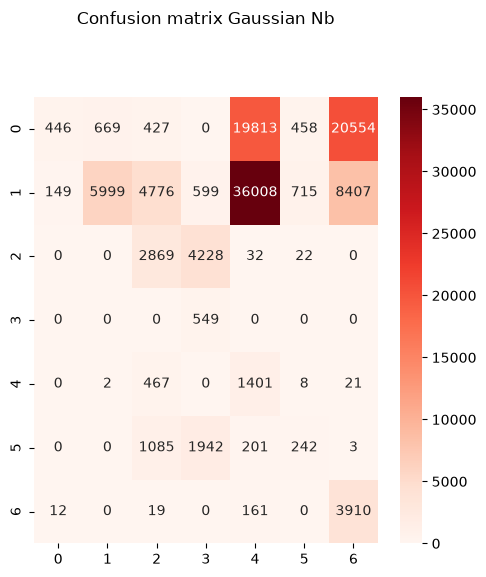

In [5]:
fig = plt.figure(figsize = (5,5))
ax = fig.gca()

cnf_matrix_log = confusion_matrix(y_test, y_pred_gnb)
sns.heatmap(pd.DataFrame(cnf_matrix_log), annot=True,cmap="Reds" , fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix Gaussian Nb\n', y=1.1)

In [6]:
gnb_pca = GaussianNB()
start_pca = time.time()
gnb_pca.fit(X_train_pca, y_train_pca)
time_pca = time.time() - start_pca

y_pred_gnb_pca = gnb_pca.predict(X_test_pca)
print(f'{time_pca}')
y_pred_gnb_pca

0.25433969497680664


array([7, 7, 5, ..., 5, 5, 7], shape=(116194,))

In [7]:
print(classification_report(y_test_pca, y_pred_gnb_pca))

              precision    recall  f1-score   support

           1       0.73      0.01      0.02     42367
           2       0.90      0.11      0.19     56653
           3       0.30      0.40      0.34      7151
           4       0.08      1.00      0.14       549
           5       0.02      0.74      0.05      1899
           6       0.18      0.06      0.09      3473
           7       0.12      0.95      0.21      4102

    accuracy                           0.13    116194
   macro avg       0.33      0.47      0.15    116194
weighted avg       0.73      0.13      0.13    116194



Text(0.5, 1.1, 'Confusion matrix Gaussian Nb\n')

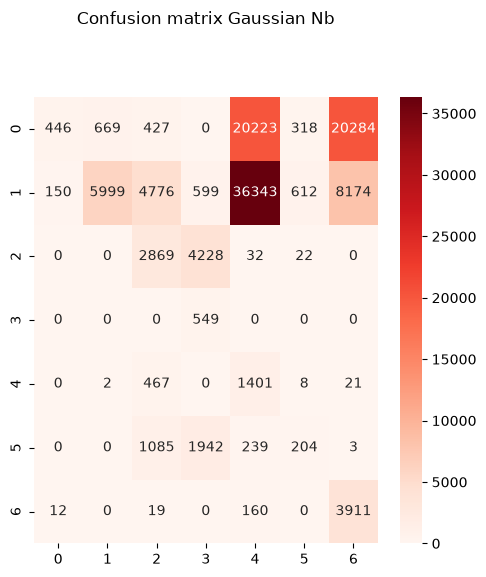

In [8]:
fig = plt.figure(figsize = (5,5))
ax = fig.gca()

cnf_matrix_log = confusion_matrix(y_test_pca, y_pred_gnb_pca)
sns.heatmap(pd.DataFrame(cnf_matrix_log), annot=True,cmap="Reds" , fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix Gaussian Nb\n', y=1.1)

In [9]:
gnb_t = GaussianNB()
start_t = time.time()
gnb_t.fit(X_train_t, y_train_t)
time_t = time.time() - start_t

y_pred_gnb_t = gnb_t.predict(X_test_t)
print(f'{time_t}')
y_pred_gnb_t

0.2464463710784912


array([7, 7, 5, ..., 5, 5, 7], shape=(116194,))

In [10]:
print(classification_report(y_test_t, y_pred_gnb_t))

              precision    recall  f1-score   support

           1       0.66      0.01      0.03     42367
           2       0.90      0.11      0.19     56653
           3       0.30      0.40      0.34      7151
           4       0.08      1.00      0.14       549
           5       0.03      0.74      0.05      1899
           6       0.16      0.08      0.10      3473
           7       0.11      0.95      0.20      4102

    accuracy                           0.13    116194
   macro avg       0.32      0.47      0.15    116194
weighted avg       0.71      0.13      0.13    116194



Text(0.5, 1.1, 'Confusion matrix Gaussian Nb\n')

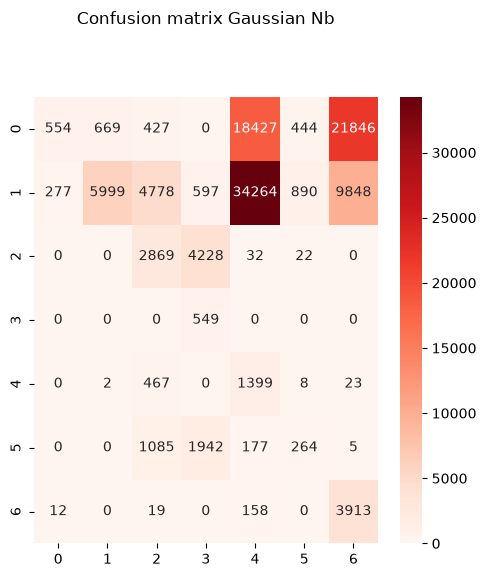

In [11]:
fig = plt.figure(figsize = (5,5))
ax = fig.gca()

cnf_matrix_log = confusion_matrix(y_test_t, y_pred_gnb_t)
sns.heatmap(pd.DataFrame(cnf_matrix_log), annot=True,cmap="Reds" , fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix Gaussian Nb\n', y=1.1)

## Анализ

В вышепоказанном разделе представлены результаты обучения модели наивного байеса на основе гауссовского классификатора на 3 выборках. Как и в прошлой работе для экспериментов были взяты выборки с 3 этапов подготовки: до отбора признаков, после отбора признаков и после выделения компонент. Все выборки предварительно прошли сэмплинг методами UnderSampler и SMOTENC.

На стандартных параметрах все выборки показали плохой результат в 13% точности, при этом все модеил активно путают классы 0 и 4. Однако, после прочтения выдержки со Stack Overflow:

> A Gaussian curve can serve as a "low pass" filter, allowing only the samples close to its mean to "pass." In the context of Naive Bayes, assuming a Gaussian distribution is essentially giving more weights to the samples closer to the distribution mean. This might or might not be appropriate depending if what you want to predict follows a normal distribution. The variable, var_smoothing, artificially adds a user-defined value to the distribution's variance (whose default value is derived from the training data set). This essentially widens (or "smooths") the curve and accounts for more samples that are further away from the distribution mean. (Гауссова кривая может служить фильтром нижних частот, пропуская только те образцы, которые близки к её среднему значению. В контексте наивного байесовского классификатора предположение о гауссовом распределении по сути означает присвоение большего веса образцам, близким к среднему значению распределения. Это может быть уместно или нет, в зависимости от того, следует ли то, что вы хотите предсказать, нормальному распределению. Переменная var_smoothing искусственно добавляет заданное пользователем значение к дисперсии распределения (значение по умолчанию которого определяется на основе обучающего набора данных). Это, по сути, расширяет (или «сглаживает») кривую и учитывает больше образцов, которые находятся дальше от среднего значения распределения.)

было принято решение провести тестирование модели на одной из выборок с уменьшенным параметров var_smoothing, который отвечает за расширение гауссовской кривой.

In [12]:
gnb_t = GaussianNB(var_smoothing=1e-2)
start_t = time.time()
gnb_t.fit(X_train_t, y_train_t)
time_t = time.time() - start_t

y_pred_gnb_t = gnb_t.predict(X_test_t)
print(f'{time_t}')
y_pred_gnb_t

0.2562541961669922


array([1, 7, 1, ..., 2, 1, 1], shape=(116194,))

In [13]:
print(classification_report(y_test_t, y_pred_gnb_t))

              precision    recall  f1-score   support

           1       0.58      0.69      0.63     42367
           2       0.79      0.34      0.48     56653
           3       0.57      0.61      0.59      7151
           4       0.19      0.92      0.32       549
           5       0.08      0.72      0.15      1899
           6       0.32      0.45      0.38      3473
           7       0.34      0.84      0.49      4102

    accuracy                           0.51    116194
   macro avg       0.41      0.65      0.43    116194
weighted avg       0.66      0.51      0.53    116194



Text(0.5, 1.1, 'Confusion matrix Gaussian Nb\n')

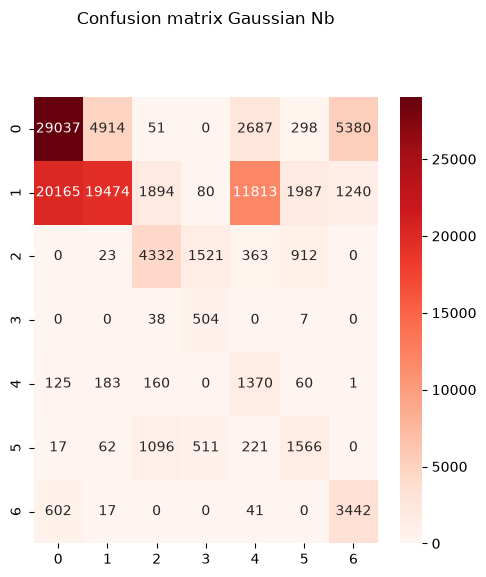

In [14]:
fig = plt.figure(figsize = (5,5))
ax = fig.gca()

cnf_matrix_log = confusion_matrix(y_test_t, y_pred_gnb_t)
sns.heatmap(pd.DataFrame(cnf_matrix_log), annot=True,cmap="Reds" , fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix Gaussian Nb\n', y=1.1)

## Анализ

Здесь можем наблюдать ситуацию, при которой точность модели сильно вырастает с 13 до 51 процента. Хотя модель все равно продолжает активно "путать" классы, но благодаря расширению количества образцов, которые находятся дальше от среднего значения распределения точность вырастает.

По [статье на Habr](https://habr.com/ru/articles/802435/) гауссовский классификатор предназначен в основном для работы с непрерынвми признаками. При этом в используемом датасете бошинство признаков, независимо от выборки - бинарные, а следственно далеки от нормального распредления. Это и может быть причиной малой точности.

## 2.2. Анализ априорных вероятностей (средний уровень)

In [15]:
prior_table = pd.DataFrame({
    'Класс на выборке 1': gnb.classes_,
    'Априорная вероятность на выборке 1': gnb.class_prior_,
    'Класс на выборке 2': gnb_pca.classes_,
    'Априорная вероятность на выборке 2': gnb_pca.class_prior_,
    'Класс на выборке 3': gnb_t.classes_,
    'Априорная вероятность на выборке 3': gnb_t.class_prior_
})
display(prior_table)

,Класс на выборке 1,Априорная вероятность на выборке 1,Класс на выборке 2,Априорная вероятность на выборке 2,Класс на выборке 3,Априорная вероятность на выборке 3
0,1,0.142857,1,0.142857,1,0.142857
1,2,0.142857,2,0.142857,2,0.142857
2,3,0.142857,3,0.142857,3,0.142857
3,4,0.142857,4,0.142857,4,0.142857
4,5,0.142857,5,0.142857,5,0.142857
5,6,0.142857,6,0.142857,6,0.142857
6,7,0.142857,7,0.142857,7,0.142857


## Анализ

Оценим априорные вероятности классов. По таблице видно, что во всех трёх выборках представлены семь классов, и априорная вероятность каждого из них составляет 0.142857 (примерно 14,3%). Значения полностью совпадают для всех трёх выборок. Это означает, что классы представлены в данных равномерно, то есть каждый класс имеет одинаковую долю объектов. Следовательно, ни один из классов не имеет преимущества по частоте встречаемости перед остальными. Такое распределение позволяет модели учитывать классы на равных условиях при расчёте апостериорных вероятностей.

In [16]:
y_proba_gnb = gnb.predict_proba(X_test)
n_examples = min(10, len(X_test))
prob_examples = pd.DataFrame(
    y_proba_gnb[:n_examples],
    columns=[f'P(класс {cls})' for cls in gnb.classes_]
)
display(prob_examples)

,P(класс 1),P(класс 2),P(класс 3),P(класс 4),P(класс 5),P(класс 6),P(класс 7)
0,1.028207e-16,1.688718e-33,0.000000e+00,0.0,2.242083e-13,3.684969e-06,9.999963e-01
1,2.142007e-39,4.046331e-122,0.000000e+00,0.0,0.000000e+00,0.000000e+00,1.000000e+00
2,3.016353e-32,4.496979e-48,0.000000e+00,0.0,1.000000e+00,0.000000e+00,2.244586e-08
3,1.619912e-38,9.042829e-50,0.000000e+00,0.0,1.000000e+00,0.000000e+00,2.754957e-25
4,6.688530e-34,1.596738e-47,0.000000e+00,0.0,1.000000e+00,0.000000e+00,1.089040e-09
5,5.834226e-30,4.734605e-45,0.000000e+00,0.0,1.550312e-03,2.138827e-04,9.982358e-01
6,1.140966e-31,5.527625e-46,0.000000e+00,0.0,9.999516e-01,0.000000e+00,4.835638e-05
7,0.000000e+00,2.339940e-85,1.000000e+00,0.0,3.047953e-22,2.154431e-23,2.855503e-85
8,6.806368e-30,1.369195e-44,1.456107e-44,0.0,2.432762e-01,6.163278e-16,7.567238e-01
9,6.299348e-32,3.598525e-46,0.000000e+00,0.0,9.999912e-01,0.000000e+00,8.840140e-06


In [17]:
y_proba_gnb_t = gnb_t.predict_proba(X_test_t)
n_examples = min(10, len(X_test_t))
prob_examples_t = pd.DataFrame(
    y_proba_gnb_t[:n_examples],
    columns=[f'P(класс {cls})' for cls in gnb_t.classes_]
)
display(prob_examples_t)

,P(класс 1),P(класс 2),P(класс 3),P(класс 4),P(класс 5),P(класс 6),P(класс 7)
0,9.337169e-01,6.574835e-02,1.540916e-09,8.866830e-39,6.965230e-05,4.058400e-07,4.646555e-04
1,6.423518e-05,2.495603e-11,1.637230e-16,8.191466e-56,5.890003e-18,6.312743e-17,9.999358e-01
2,8.765461e-01,1.104890e-01,5.009649e-28,1.930164e-47,1.296395e-02,6.257693e-26,9.831562e-07
3,3.851913e-03,1.037696e-01,6.495347e-23,3.572111e-43,8.923785e-01,3.046718e-23,9.240690e-09
4,9.757027e-02,9.000595e-01,4.170436e-36,1.494577e-60,2.370189e-03,6.197656e-34,6.072388e-08
5,7.483767e-01,1.554347e-01,1.042390e-11,1.250518e-46,4.272817e-05,2.520016e-06,9.614331e-02
6,4.714637e-01,4.507162e-01,5.490526e-21,3.330316e-38,7.778427e-02,6.345498e-21,3.579850e-05
7,3.073193e-11,3.606730e-07,9.506042e-01,1.513530e-26,4.825812e-02,1.137285e-03,1.154939e-14
8,7.673897e-01,2.256655e-01,4.832331e-12,3.846984e-45,2.109505e-04,1.501346e-09,6.733926e-03
9,4.531971e-01,5.467758e-01,7.065051e-37,1.354690e-77,1.348487e-05,4.393408e-38,1.369369e-05


## Анализ

По таблице видно, что модель GaussianNB для большинства объектов определяет один класс с очень высокой вероятностью. Например, для объектов 0 и 1 вероятность принадлежности к классу 7 практически равна 1. Для объектов 2, 3, 4, 6 и 9 модель с высокой уверенностью выбирает класс 5. Для объекта 7 вероятность принадлежности к классу 3 равна 1.

В некоторых случаях модель распределяет вероятности между несколькими классами. Например, для объекта 8 вероятность класса 7 составляет около 75,7%, а класса 5 - около 24,3%. Это говорит о том, что модель менее уверена в данном предсказании. В целом значения показывают, что GaussianNB часто делает достаточно уверенные прогнозы, однако высокая апостериорная вероятность сама по себе не гарантирует правильность классификации.

Оценка проводилась только для одной модели на самой последней на текущей момент выборке, так ка все модели получили примерно одинаковые оценки качества.

Для выборки 3 (до отбора признаков) ситуация другая. Здесь модель GaussianNB распределяет вероятности между классами по-разному для каждого объекта. Для объекта 0 наиболее вероятен класс 1 с вероятностью около 93,4%, а для объекта 1 - класс 7 с вероятностью практически 100%. Для объектов 2 и 8 модель также отдаёт предпочтение классу 1, а для объекта 3 - классу 5 с вероятностью около 89,2%. Для объекта 4 наиболее вероятен класс 2 (90%), а для объекта 7 - класс 3 (95,1%). При этом для объектов 5, 6 и 9 вероятности распределены между несколькими классами более равномерно. Например, для объекта 6 вероятность класса 1 составляет около 47,1%, а класса 2 - около 45,1%. Это говорит о том, что модель не может уверенно определить единственный класс для данного объекта. В целом модель чаще выделяет один наиболее вероятный класс, но для некоторых объектов её предсказания менее уверенные.

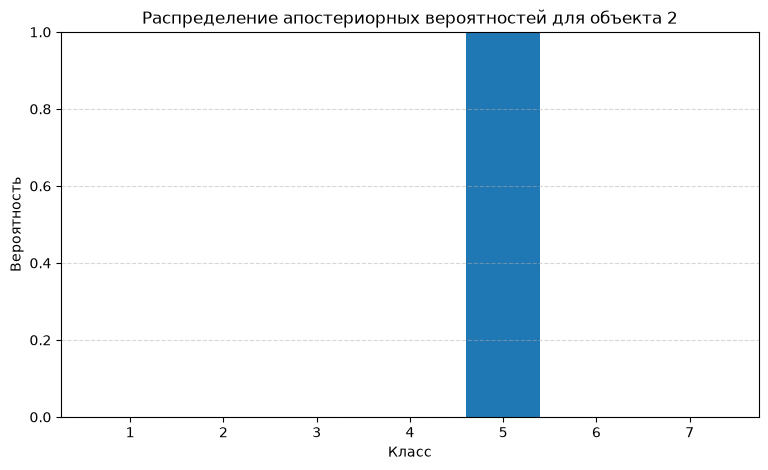

In [18]:
probabilities = y_proba_gnb[2]
classes = np.arange(1, len(probabilities) + 1)
plt.figure(figsize=(9, 5))
plt.bar(classes, probabilities)

plt.xlabel('Класс')
plt.ylabel('Вероятность')
plt.title('Распределение апостериорных вероятностей для объекта 2')
plt.xticks(classes)
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

In [19]:
print(f'Истинный _t {y_test[0]}', f'Предсказанный _t {y_pred_gnb[0]}', sep='\t')

Истинный _t 1	Предсказанный _t 7


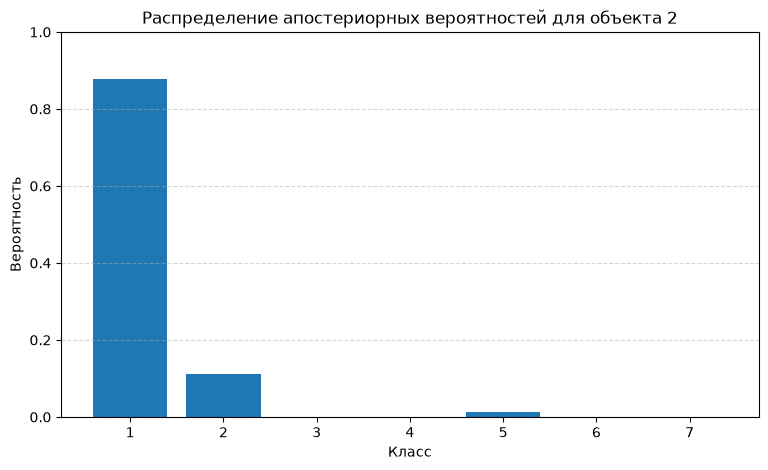

In [20]:
probabilities_t = y_proba_gnb_t[2]
classes_t = np.arange(1, len(probabilities_t) + 1)
plt.figure(figsize=(9, 5))
plt.bar(classes_t, probabilities_t)

plt.xlabel('Класс')
plt.ylabel('Вероятность')
plt.title('Распределение апостериорных вероятностей для объекта 2')
plt.xticks(classes_t)
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

In [21]:
print(f'Истинный _t {y_test_t[0]}', f'Предсказанный _t {y_pred_gnb_t[0]}', sep='\t')

Истинный _t 1	Предсказанный _t 1


## Анализ

Графики подтверждают сделанные ранее гипотезы. Здесь видно, что первая модель делает полную ставку на класс 5, в отличие от третьей, которая большую вероятность отдает классу 1, распределяя остатки на классы 2 и 5. При этом конкретно для данного объекта истинный класс предсказала третья модель.

In [22]:
y_true = np.array(y_test)
y_pred = np.array(y_pred_gnb)

wrong_indices = np.where(y_true != y_pred)[0]
print("Количество ошибок:", len(wrong_indices))
print("Индексы неправильно классифицированных объектов:", wrong_indices)
wrong_indicies = np.random.choice(wrong_indices, size=10)
for i in wrong_indicies:
    print(f"Объект {i}: истинный класс — {y_true[i]}, "
          f"предсказанный класс — {y_pred[i]}")

Количество ошибок: 100778
Индексы неправильно классифицированных объектов: [     0      2      3 ... 116191 116192 116193]
Объект 23098: истинный класс — 2, предсказанный класс — 5
Объект 87750: истинный класс — 3, предсказанный класс — 4
Объект 30663: истинный класс — 1, предсказанный класс — 5
Объект 34282: истинный класс — 1, предсказанный класс — 7
Объект 55759: истинный класс — 2, предсказанный класс — 5
Объект 107937: истинный класс — 2, предсказанный класс — 5
Объект 20236: истинный класс — 2, предсказанный класс — 7
Объект 77683: истинный класс — 2, предсказанный класс — 7
Объект 28249: истинный класс — 2, предсказанный класс — 7
Объект 76412: истинный класс — 6, предсказанный класс — 4


In [23]:
classes = np.arange(1, y_proba_gnb.shape[1] + 1)
wrong_results = pd.DataFrame(
    y_proba_gnb[wrong_indicies],
    columns=[f"P(класс {c})" for c in classes],
    index=wrong_indicies
)
display(wrong_results)

,P(класс 1),P(класс 2),P(класс 3),P(класс 4),P(класс 5),P(класс 6),P(класс 7)
23098,7.375793e-32,7.122806e-46,0.000000e+00,0.0,9.999998e-01,0.000000e+00,1.734716e-07
87750,0.000000e+00,0.000000e+00,2.596936e-15,1.0,0.000000e+00,5.130757e-33,0.000000e+00
30663,3.029518e-29,5.730697e-44,0.000000e+00,0.0,8.958469e-01,0.000000e+00,1.041531e-01
34282,5.819488e-31,4.939397e-46,8.906290e-47,0.0,3.658966e-05,3.465123e-18,9.999634e-01
55759,4.716949e-11,1.293229e-23,0.000000e+00,0.0,1.000000e+00,0.000000e+00,0.000000e+00
107937,3.581746e-31,3.503026e-46,0.000000e+00,0.0,1.000000e+00,1.633116e-47,2.039399e-17
20236,4.137864e-29,5.892281e-44,0.000000e+00,0.0,1.138174e-01,0.000000e+00,8.861826e-01
77683,3.386602e-31,2.341808e-46,3.840904e-47,0.0,3.348945e-06,1.377678e-18,9.999967e-01
28249,2.673859e-15,7.029536e-32,0.000000e+00,0.0,1.033773e-11,2.381168e-03,9.976188e-01
76412,0.000000e+00,2.134442e-107,1.041922e-14,1.0,0.000000e+00,2.673231e-32,0.000000e+00


## Анализ

Всего на первой выборке модель совершила при классификации 100778, что очень много при объеме тестовой выборке в 116194. При этом по таблице апостериорных вероятностей видно, что модель часто делает предсказания с очень высокой уверенностью. Например, для объекта 0 вероятность класса 7 составляет около 99,9996%, а для объектов 1–3 вероятность класса 5 практически равна 100%. Это говорит о том, что распределения признаков разных классов могут быть похожими, из-за чего модели сложно правильно разделять объекты. Следовательно, высокая апостериорная вероятность не всегда свидетельствует о правильности классификации. "Пограничных объектов" во всех рассмотренных выборках из числа ошибочных предсказаний не встречаются.

In [24]:
y_true_pca = np.array(y_test_pca)
y_pred_pca = np.array(y_pred_gnb_pca)

wrong_indices_pca = np.where(y_true_pca != y_pred_pca)[0]
print("Количество ошибок:", len(wrong_indices_pca))
print("Индексы неправильно классифицированных объектов:", wrong_indices_pca)
wrong_indicies_pca = np.random.choice(wrong_indices_pca, size=10)
for i in wrong_indicies_pca:
    print(f"Объект {i}: истинный класс — {y_true_pca[i]}, "
          f"предсказанный класс — {y_pred_pca[i]}")

Количество ошибок: 100815
Индексы неправильно классифицированных объектов: [     0      2      3 ... 116191 116192 116193]
Объект 100355: истинный класс — 1, предсказанный класс — 5
Объект 34250: истинный класс — 1, предсказанный класс — 7
Объект 14182: истинный класс — 2, предсказанный класс — 5
Объект 33927: истинный класс — 1, предсказанный класс — 5
Объект 89627: истинный класс — 2, предсказанный класс — 3
Объект 5167: истинный класс — 2, предсказанный класс — 5
Объект 24124: истинный класс — 1, предсказанный класс — 7
Объект 15298: истинный класс — 2, предсказанный класс — 5
Объект 2363: истинный класс — 2, предсказанный класс — 5
Объект 23937: истинный класс — 1, предсказанный класс — 7


In [25]:
y_proba_gnb_pca = gnb_pca.predict_proba(X_test_pca)
classes_pca = np.arange(1, y_proba_gnb_pca.shape[1] + 1)
wrong_results_pca = pd.DataFrame(
    y_proba_gnb_pca[wrong_indicies_pca],
    columns=[f"P(класс {c})" for c in classes],
    index=wrong_indicies_pca
)
display(wrong_results_pca)

,P(класс 1),P(класс 2),P(класс 3),P(класс 4),P(класс 5),P(класс 6),P(класс 7)
100355,5.852466e-37,1.579702e-48,0.000000e+00,0.0,1.000000e+00,0.000000e+00,2.214725e-22
34250,1.335402e-28,9.607907e-50,0.000000e+00,0.0,0.000000e+00,0.000000e+00,1.000000e+00
14182,6.412682e-30,2.029187e-44,3.803460e-44,0.0,8.101560e-01,1.091528e-15,1.898440e-01
33927,1.929475e-35,2.982666e-47,0.000000e+00,0.0,1.000000e+00,0.000000e+00,4.039710e-20
89627,4.432275e-108,1.082495e-68,1.000000e+00,0.0,1.817783e-17,4.029299e-20,0.000000e+00
5167,2.998018e-37,1.006300e-48,0.000000e+00,0.0,1.000000e+00,0.000000e+00,1.795241e-23
24124,5.224149e-30,1.009505e-44,8.067564e-45,0.0,4.401959e-02,1.926612e-16,9.559804e-01
15298,3.570471e-31,1.877473e-45,0.000000e+00,0.0,9.999640e-01,0.000000e+00,3.602206e-05
2363,6.963342e-31,4.012990e-45,4.335158e-44,0.0,9.985881e-01,1.499321e-15,1.411859e-03
23937,8.310107e-06,2.268541e-26,0.000000e+00,0.0,0.000000e+00,0.000000e+00,9.999917e-01


In [26]:
y_true_t = np.array(y_test_t)
y_pred_t = np.array(y_pred_gnb_t)

wrong_indices_t = np.where(y_true_t != y_pred_t)[0]
print("Количество ошибок:", len(wrong_indices_t))
print("Индексы неправильно классифицированных объектов:", wrong_indices_t)
wrong_indicies_t = np.random.choice(wrong_indices_t, size=10)
for i in wrong_indicies_t:
    print(f"Объект {i}: истинный класс — {y_true_t[i]}, "
          f"предсказанный класс — {y_pred_t[i]}")

Количество ошибок: 56469
Индексы неправильно классифицированных объектов: [     2      3      4 ... 116181 116183 116184]
Объект 41359: истинный класс — 2, предсказанный класс — 5
Объект 24042: истинный класс — 1, предсказанный класс — 2
Объект 14301: истинный класс — 2, предсказанный класс — 5
Объект 57028: истинный класс — 2, предсказанный класс — 5
Объект 88928: истинный класс — 2, предсказанный класс — 1
Объект 44325: истинный класс — 2, предсказанный класс — 5
Объект 104625: истинный класс — 2, предсказанный класс — 5
Объект 48223: истинный класс — 1, предсказанный класс — 2
Объект 83002: истинный класс — 3, предсказанный класс — 5
Объект 42716: истинный класс — 2, предсказанный класс — 1


In [27]:
y_proba_gnb_t = gnb_t.predict_proba(X_test_t)
classes_t = np.arange(1, y_proba_gnb_t.shape[1] + 1)
wrong_results_t = pd.DataFrame(
    y_proba_gnb_t[wrong_indicies_t],
    columns=[f"P(класс {c})" for c in classes],
    index=wrong_indicies_t
)
display(wrong_results_t)

,P(класс 1),P(класс 2),P(класс 3),P(класс 4),P(класс 5),P(класс 6),P(класс 7)
41359,1.124422e-09,7.440585e-04,5.831768e-02,1.401743e-24,9.307044e-01,1.023386e-02,7.871922e-17
24042,2.132746e-01,7.844277e-01,5.815460e-16,4.541368e-30,2.297747e-03,3.328401e-11,1.863125e-10
14301,1.441617e-07,8.489248e-03,1.928969e-02,2.599424e-30,9.690901e-01,3.130854e-03,4.459824e-12
57028,8.900030e-02,2.696548e-01,9.219588e-09,1.634865e-34,6.386974e-01,7.475383e-07,2.646742e-03
88928,9.983206e-01,1.679378e-03,4.992742e-29,1.008397e-57,5.878302e-11,1.503844e-29,2.147229e-09
44325,1.246792e-07,1.949091e-03,5.403983e-10,3.227405e-35,9.980507e-01,3.939797e-08,1.165947e-10
104625,2.069089e-01,3.260953e-01,2.754794e-09,2.981475e-34,4.649879e-01,1.985051e-03,2.285951e-05
48223,1.661571e-06,9.999983e-01,4.009159e-39,1.002347e-60,3.542280e-12,1.567190e-35,6.091372e-15
83002,1.426474e-12,3.334231e-07,1.525426e-07,2.032056e-27,9.958381e-01,4.161364e-03,2.786235e-20
42716,9.997544e-01,2.454959e-04,5.364440e-34,3.143275e-76,4.058695e-16,2.781199e-35,1.315800e-07


## Анализ 

Для моделей обученных на двух других выборках ситуация повторяется. Модель чаще всего, даже в абсютном большинстве выбирает классы с высокой уверенностью, не распределяя вероятности между несколькими классами. 

## 2.3. Сравнение предсказаний и истинных значений (повышенный уровень)

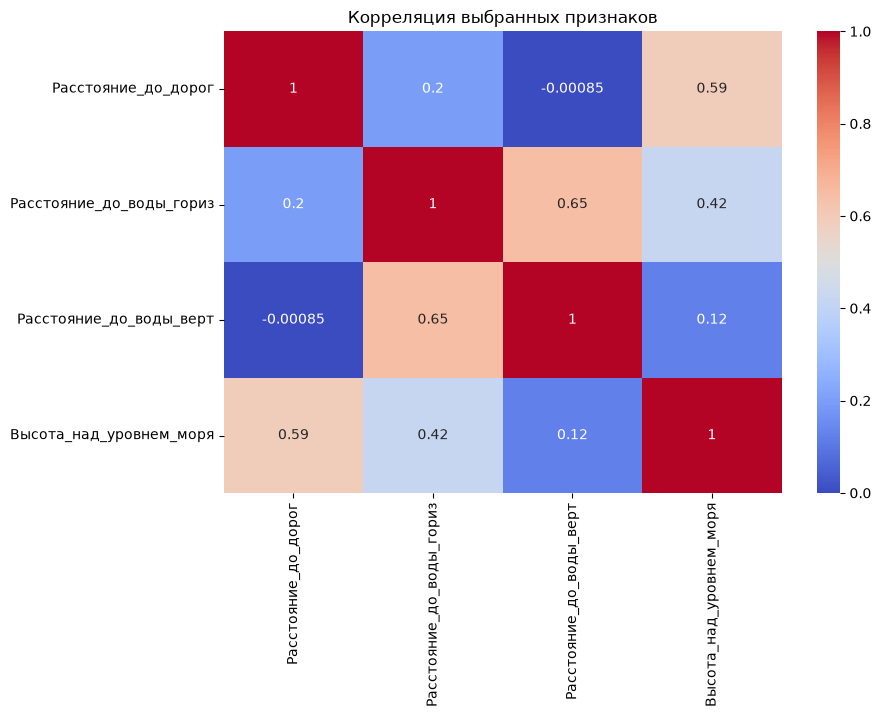

In [28]:
selected_features_t = [
    'Расстояние_до_дорог',
    'Расстояние_до_воды_гориз',
    'Расстояние_до_воды_верт',
    'Высота_над_уровнем_моря',
]

corr_t = X_train_t[selected_features_t].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(corr_t, annot=True, cmap='coolwarm')
plt.title('Корреляция выбранных признаков')
plt.show()

## Анализ 

Для рассмотрения зависимых признаков была взята самая старая выборка до отбора признаков, так как здесь сохранились непрервыные признаки, которые с практической точки зрения интересны в данной ситуации. Из рассмотрения были исключены все бинарные столбцы, так как они по определению являются взаимоисключаищими и по опыту не коррелируют.

По тепловой карте видим, что признаки, связанные с расстояние умеют неплохие зависимости между собой.

Наивный байесовский классификатор предполагает, что признаки условно независимы друг от друга при известном классе. Если это условие нарушается, модель может иметь плохую точность и учитывать одну информацию несколько раз, поскольку вклад зависимых признаков учитывается отдельно. Это может приводить к тому, что модель слишком уверенно выбирает определённый класс. В некоторых случаях итоговое предсказание может измениться, если совместное влияние признаков будет оценено неправильно. Таким образом, зависимость признаков не обязательно приводит к ошибке, но может снижать точность вероятностных оценок и влиять на качество классификации.

In [29]:
bnb = BernoulliNB()
start = time.time()
bnb.fit(X_train, y_train)
time_bnb = time.time() - start

y_pred_bnb = bnb.predict(X_test)
y_pred_bnb

array([1, 7, 5, ..., 2, 1, 1], shape=(116194,))

In [30]:
print(classification_report(y_test, y_pred_bnb))

              precision    recall  f1-score   support

           1       0.59      0.68      0.63     42367
           2       0.80      0.33      0.47     56653
           3       0.55      0.30      0.39      7151
           4       0.17      0.86      0.29       549
           5       0.07      0.67      0.13      1899
           6       0.28      0.55      0.37      3473
           7       0.27      0.85      0.41      4102

    accuracy                           0.49    116194
   macro avg       0.39      0.61      0.38    116194
weighted avg       0.66      0.49      0.51    116194



Text(0.5, 1.1, 'Confusion matrix Bernoulli Nb\n')

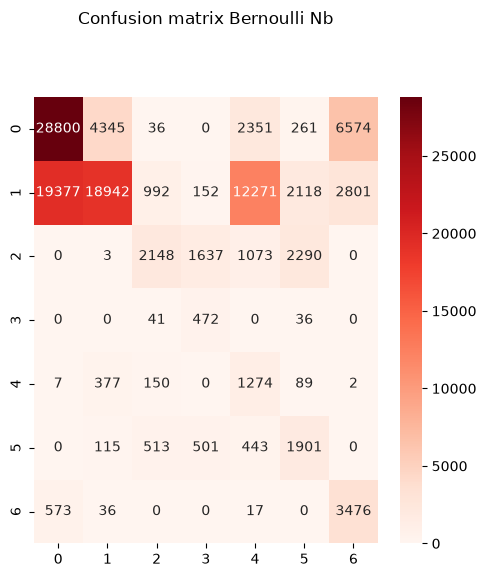

In [31]:
fig = plt.figure(figsize = (5,5))
ax = fig.gca()

cnf_matrix_log = confusion_matrix(y_test, y_pred_bnb)
sns.heatmap(pd.DataFrame(cnf_matrix_log), annot=True,cmap="Reds" , fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix Bernoulli Nb\n', y=1.1)

In [32]:
bnb_pca = BernoulliNB()
start_pca = time.time()
bnb_pca.fit(X_train_pca, y_train_pca)
time_bnb_pca = time.time() - start_pca

y_pred_bnb_pca = bnb_pca.predict(X_test_pca)
y_pred_bnb_pca

array([1, 7, 1, ..., 1, 1, 1], shape=(116194,))

In [33]:
print(classification_report(y_test_pca, y_pred_bnb_pca))

              precision    recall  f1-score   support

           1       0.58      0.52      0.55     42367
           2       0.67      0.41      0.51     56653
           3       0.67      0.33      0.44      7151
           4       0.15      0.87      0.25       549
           5       0.06      0.62      0.11      1899
           6       0.29      0.61      0.39      3473
           7       0.41      0.81      0.54      4102

    accuracy                           0.47    116194
   macro avg       0.40      0.60      0.40    116194
weighted avg       0.60      0.47      0.51    116194



Text(0.5, 1.1, 'Confusion matrix Bernoulli Nb\n')

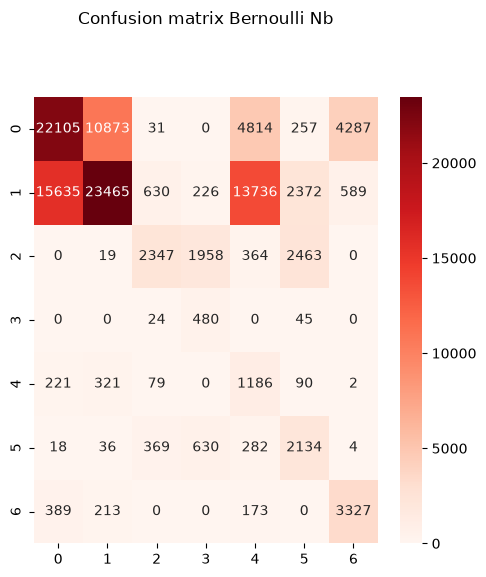

In [34]:
fig = plt.figure(figsize = (5,5))
ax = fig.gca()

cnf_matrix_log = confusion_matrix(y_test_pca, y_pred_bnb_pca)
sns.heatmap(pd.DataFrame(cnf_matrix_log), annot=True,cmap="Reds" , fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix Bernoulli Nb\n', y=1.1)

In [35]:
bnb_t = BernoulliNB()
start_t = time.time()
bnb_t.fit(X_train_t, y_train_t)
time_bnb_t = time.time() - start_t

y_pred_bnb_t = bnb_t.predict(X_test_t)
y_pred_bnb_t

array([1, 7, 2, ..., 2, 1, 1], shape=(116194,))

In [36]:
print(classification_report(y_test_t, y_pred_bnb_t))

              precision    recall  f1-score   support

           1       0.60      0.65      0.62     42367
           2       0.79      0.33      0.46     56653
           3       0.55      0.35      0.42      7151
           4       0.17      0.85      0.29       549
           5       0.08      0.73      0.15      1899
           6       0.28      0.57      0.38      3473
           7       0.23      0.86      0.37      4102

    accuracy                           0.48    116194
   macro avg       0.39      0.62      0.38    116194
weighted avg       0.65      0.48      0.51    116194



Text(0.5, 1.1, 'Confusion matrix Bernoulli Nb\n')

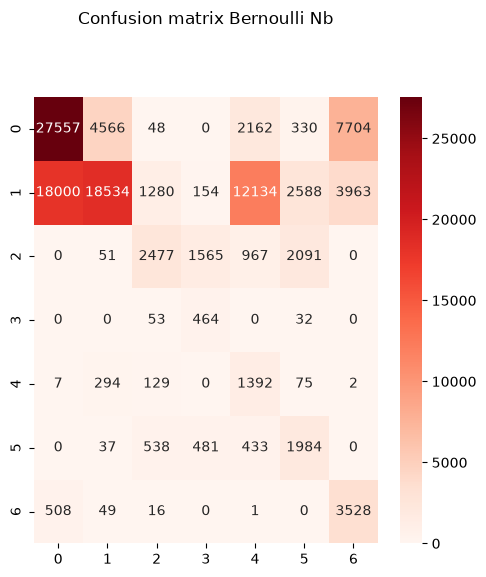

In [37]:
fig = plt.figure(figsize = (5,5))
ax = fig.gca()

cnf_matrix_log = confusion_matrix(y_test_t, y_pred_bnb_t)
sns.heatmap(pd.DataFrame(cnf_matrix_log), annot=True,cmap="Reds" , fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix Bernoulli Nb\n', y=1.1)

## Анализ 

В качестве второго классификатора был выбран вариант на основе распределения Бернулли, так как он по [статье](https://habr.com/ru/articles/802435/) наилучшим образом подходит для бинарных признаков, коих в каждой выборке большинство. 

Здесь видим, что результат, по сравнению с распределением Гаусса сильно улучшился и достинг 49% на выборке после отбора признаков без дополнительной настройки параметров. Результат, с учетом первых полученны неплохой, однако полнота (recall) для некоторых классов, как например для третьего (30%), оставляем желать лучшего. Возможно это связано с тем, что это миноритарный класс с большим количество синтетики на данный момент.

In [38]:
y_proba_bnb = bnb.predict_proba(X_test)
y_true = np.array(y_test)
y_pred = np.array(y_pred_bnb)

wrong_indices = np.where(y_true != y_pred)[0]
print("Количество ошибок:", len(wrong_indices))
print("Индексы неправильно классифицированных объектов:", wrong_indices)
wrong_indicies_t = np.random.choice(wrong_indices_t, size=10)
for i in wrong_indicies_t:
    print(f"Объект {i}: истинный класс — {y_true_t[i]}, "
          f"предсказанный класс — {y_pred_t[i]}")

Количество ошибок: 59181
Индексы неправильно классифицированных объектов: [     2      3      4 ... 116184 116187 116188]
Объект 82720: истинный класс — 4, предсказанный класс — 3
Объект 93388: истинный класс — 2, предсказанный класс — 5
Объект 31574: истинный класс — 2, предсказанный класс — 1
Объект 65138: истинный класс — 2, предсказанный класс — 5
Объект 98739: истинный класс — 2, предсказанный класс — 5
Объект 94446: истинный класс — 1, предсказанный класс — 2
Объект 17082: истинный класс — 2, предсказанный класс — 5
Объект 53717: истинный класс — 2, предсказанный класс — 1
Объект 30195: истинный класс — 2, предсказанный класс — 1
Объект 34347: истинный класс — 1, предсказанный класс — 5


In [39]:
classes = np.arange(1, y_proba_bnb.shape[1] + 1)
wrong_results = pd.DataFrame(
    y_proba_bnb[wrong_indicies],
    columns=[f"P(класс {c})" for c in classes],
    index=wrong_indicies
)
display(wrong_results)

,P(класс 1),P(класс 2),P(класс 3),P(класс 4),P(класс 5),P(класс 6),P(класс 7)
23098,1.466635e-01,7.171512e-01,1.925252e-09,4.386253e-14,1.360527e-01,2.654346e-09,1.325628e-04
87750,3.548882e-10,8.408001e-07,1.847506e-01,7.135672e-01,4.090439e-09,1.016813e-01,9.329544e-12
30663,6.102269e-01,3.636299e-01,2.787753e-14,6.351270e-19,7.910026e-04,3.843478e-14,2.535222e-02
34282,4.509287e-01,2.182653e-01,2.918459e-07,1.492336e-18,1.633686e-03,1.596210e-06,3.291705e-01
55759,1.426657e-01,6.682999e-01,6.042814e-08,1.722564e-12,1.890228e-01,1.023535e-05,1.244596e-06
107937,4.891991e-02,2.120247e-01,1.030424e-04,6.913445e-13,7.255461e-01,1.281762e-02,5.886207e-04
20236,5.341188e-01,4.268648e-01,2.145735e-14,4.290829e-18,3.020388e-03,1.201137e-14,3.599608e-02
77683,4.509287e-01,2.182653e-01,2.918459e-07,1.492336e-18,1.633686e-03,1.596210e-06,3.291705e-01
28249,1.750310e-01,4.275063e-01,4.374433e-04,3.343811e-13,1.198744e-01,2.757143e-01,1.436584e-03
76412,5.428054e-09,8.866694e-05,2.743585e-01,3.329622e-02,8.642200e-08,6.922565e-01,4.468808e-13


## Анализ

Рассмотрим предсказания модель с самой большой точностью из данного раздела. По таблице можем увидеть, что BernoulliNB распределяет вероятности между классами более равномерно, чем GaussianNB в предыдущем эксперименте. В некоторых случаях модель не выделяет один класс с вероятностью, близкой к 100%, а распределяет вероятность между несколькими вариантами. Например, для объекта 73829 наиболее вероятен класс 5 с вероятностью около 47,8%, однако вероятность класса 2 составляет 39,2%. Это говорит о том, что модель не может однозначно определить класс данного объекта. Для объекта 104315 вероятности классов 2, 5 и 6 составляют примерно 33%, 29,4% и 29,1% соответственно, поэтому предсказание также является неуверенным. В то же время для некоторых объектов модель делает более уверенные предсказания. Например, для объекта 21007 вероятность класса 1 составляет около 92,2%.

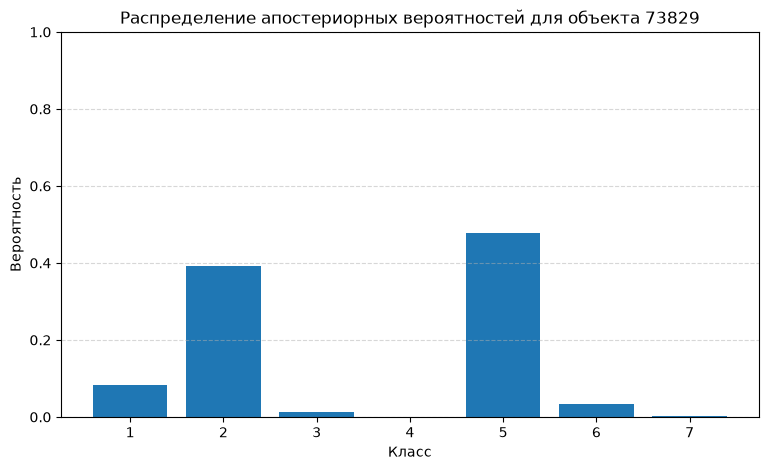

In [40]:
probabilities_bnb = y_proba_bnb[73829]
classes_bnb = np.arange(1, len(probabilities_bnb) + 1)
plt.figure(figsize=(9, 5))
plt.bar(classes, probabilities_bnb)

plt.xlabel('Класс')
plt.ylabel('Вероятность')
plt.title('Распределение апостериорных вероятностей для объекта 73829')
plt.xticks(classes_bnb)
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

In [41]:
display(X_test.iloc[[73829]])

,Высота_над_уровнем_моря,Зона_дикой_природы_1,Зона_дикой_природы_2,Зона_дикой_природы_3,Зона_дикой_природы_4,Освещённость_3_дня,Освещённость_9_утра,Тип_почвы_1,Тип_почвы_2,Тип_почвы_3,...,Тип_почвы_31,Тип_почвы_32,Тип_почвы_33,Тип_почвы_34,Тип_почвы_35,Тип_почвы_36,Тип_почвы_37,Тип_почвы_38,Тип_почвы_39,Тип_почвы_40
73829,-0.133959,0,0,1,0,0.089477,0.518455,0,0,0,...,0,1,0,0,0,0,0,0,0,0


## Анализ

На графике можем подробнее рассмотреть сложившееся распределение вероятностей. Здесь лучше видно, что вероятности классов 2 и 5 практически равны, но и не занимают все распределение, оставляя маленькие доли другим классам.

## Вывод. Связный текст

В ходе данной работы было выполнено обучение и анализ результатов моделей на основе теоремы Байеса. Из полученных результатов можно сделать свои выводы, однако стоит упомянуть, что байесовские и ранее рассмотренные модели используют разные подходы: если первые оценивают вероятность принадлежности к классу объекта, учитывая априорные вероятности и значения признаков, то вторые, например, логистическая регрессия, обучаются находить границы, разделяющие классы. Следственно, одним из основных преимуществ байесовских моделей является возможность получать вероятностные оценки для каждого класса. Кроме того, такие модели простые в реализации, не требуют больших вычислительных мощностей и быстро обучаются, особенно по сравнению с линейными моделями. Ограничением наверное можно назвать то, что наивные байесовские модели по своему принципу опираются на некоторые принципы. GaussianNB - на независимость признаков и нормальное распределение внутри каждого класса, что бывает трудно воспроизвести. Если признаки сильно взаимосвязаны, модель может учитывать похожую информацию несколько раз, из-за чего вероятности предсказаний могут искажаться. BernoulliNB же для адекватной работы требует числовые данные в диапазоне от 0 до 1, что может заставить нас потерять часть важной информации. Проведенный анализ показал, что байесовская модель порой может давать вполне уверенные прогнозы с неплохой точностью, сравнимой даже с более сложными линейными моделями, однако доля ошибочных предсказаний все также велика. Несмотря на ограничения такие модели способны эффективно решать задачи, где важна в первую очередь скорость обучения и получение совместных вероятностных оценок. В качестве примера таких областей можно привести анализ на наличие спама по ключевым словам или системы рекомендаций товаров и услуг, так как в этих областях выборки сравнительно малые, базу можно пополнять постоянно, а точность не настолько критична как в медицине. Таким образом, выбор между байесовскими и дискриминативными моделями зависит в большей степень от целей и исходных данных.